In [ ]:
!pip install pysindy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.0/121.0 kB 7.3 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.cm import rainbow
import numpy as np
from scipy.integrate import solve_ivp
from scipy.io import loadmat
from pysindy.utils import linear_damped_SHO
from pysindy.utils import cubic_damped_SHO
from pysindy.utils import linear_3D
from pysindy.utils import hopf
from pysindy.utils import lorenz

import pysindy as ps

# ignore user warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(1000)  # Seed for reproducibility

# Integrator keywords for solve_ivp
integrator_keywords = {}
integrator_keywords['rtol'] = 1e-12
integrator_keywords['method'] = 'LSODA'
integrator_keywords['atol'] = 1e-12

In [ ]:
# Generate training data

# Parameters
k = 0.002
N = 12.5
P0 = 6.084

# Logistic growth function
def logistic(t, P):
    return k * P * (N - P)

# Time settings
dt = 0.001
t_train = np.arange(0, 100, dt)
t_train_span = (t_train[0], t_train[-1])

# Generate training data
#P_train = solve_ivp(logistic, t_train_span, [P0], t_eval=t_train).y[0]
P_train = solve_ivp(logistic, t_train_span, [P0], t_eval=t_train, **integrator_keywords).y.T

# Compute derivatives
P_dot_train_measured = np.array([logistic(0, P_train[i]) for i in range(t_train.size)])


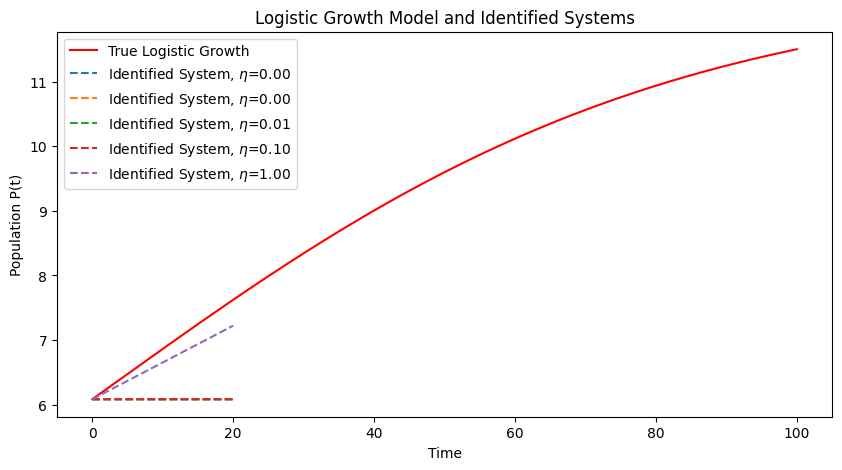

In [ ]:
# Fit the SINDy model
poly_order = 5
threshold = 0.05

# Noise levels to test
noise_levels = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
models = []
t_sim = np.arange(0, 20, dt)
P_sim = []

for eps in noise_levels:
    model = ps.SINDy(
        optimizer=ps.STLSQ(threshold=threshold),
        feature_library=ps.PolynomialLibrary(degree=poly_order),
    )
    model.fit(
        P_train,
        t=dt,
        x_dot=P_dot_train_measured + np.random.normal(scale=eps, size=P_train.shape),
        quiet=True,
    )
    models.append(model)
    P_sim.append(model.simulate(P_train[0], t_sim))

# Plot results
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_train, P_train, label='True Logistic Growth', color='r')
for i, eps in enumerate(noise_levels):
    ax.plot(t_sim, P_sim[i], label=f'Identified System, $\eta$={eps:.2f}', linestyle='--')

plt.title('Logistic Growth Model and Identified Systems')
plt.xlabel('Time')
plt.ylabel('Population P(t)')
plt.legend()
plt.show()